# Phân tích mức tiêu hao nhiên liệu

## 1. ĐỌC DỮ LIỆU

Dữ liệu `mpg.csv` gồm các thông tin như sau:

- **mpg**: Miles/(US) gallon số gallon xăng trên 1 dặm
- **cylinders:** số lượng xilanh
- **displacement:**  Displacement/ dung tích xilanh (cu.in / $inches^3$)
- **horsepower:** công suất theo mã lực
- **weight:** trọng lượng (pound)
- **acceleration:** Gia tốc
- **model_year:** Năm sản xuất
- **origin:** Xuất xứ
- **name:** Tên dòng xe


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu
df = pd.read_csv("C:/Users/mythi/Desktop/tailieu/HK1(2026-2027)/TKMT/data/mpg.csv")

# Xem 5 dòng đầu
print(df.head())

# Xem thông tin dữ liệu
print(df.info())


    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacem

## 2. TÌM HIỂU DỮ LIỆU

### 2.1 Kiểm tra có dòng nào không có dữ liệu?

In [2]:
print(df.isnull().sum())


mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


### 2.2 Xóa các dòng không có dữ liệu


In [3]:
df = df.dropna()


### 2.3 Tìm trung binh, trung vị của các thuộc tính: 'cylinders', 'horsepower', 'weight'

In [4]:
print(df[['cylinders', 'horsepower', 'weight']].mean())
print(df[['cylinders', 'horsepower', 'weight']].median())


cylinders        5.471939
horsepower     104.469388
weight        2977.584184
dtype: float64
cylinders        4.0
horsepower      93.5
weight        2803.5
dtype: float64


### 2.4 Tìm miền giá trị và miền phân vị của thuộc tính 'mpg'

In [5]:
print(df['mpg'].describe())
print(df['mpg'].describe()['max'] - df['mpg'].describe()['min'])
print(df['mpg'].describe()['75%'] - df['mpg'].describe()['25%'])


count    392.000000
mean      23.445918
std        7.805007
min        9.000000
25%       17.000000
50%       22.750000
75%       29.000000
max       46.600000
Name: mpg, dtype: float64
37.6
12.0


## 3. SO SÁNH MỨC TIÊU HAO NHIÊN LIỆU TRUNG BÌNH CỦA CÁC DÒNG XE DỰA TRÊN XUẤT XỨ

So sánh mức tiêu hao nhiên liệu trung bình của các dòng xe Mỹ, Nhật và Châu Âu

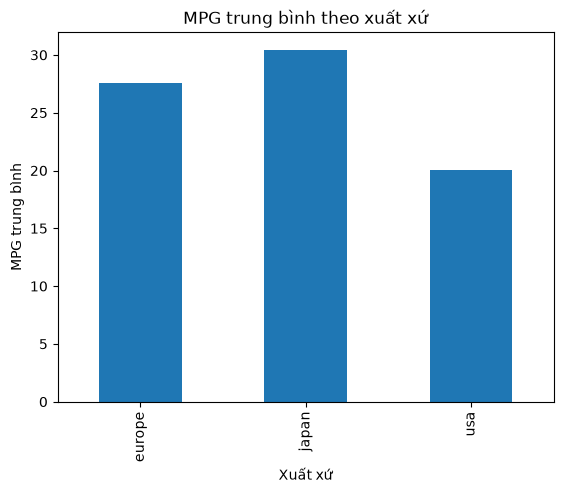

In [6]:
df.groupby('origin')['mpg'].mean().plot(kind='bar')

plt.xlabel('Xuất xứ')
plt.ylabel('MPG trung bình')
plt.title('MPG trung bình theo xuất xứ')
plt.show()



## 4. VẼ HISTOGRAM TRỌNG LƯỢNG CÁC XE

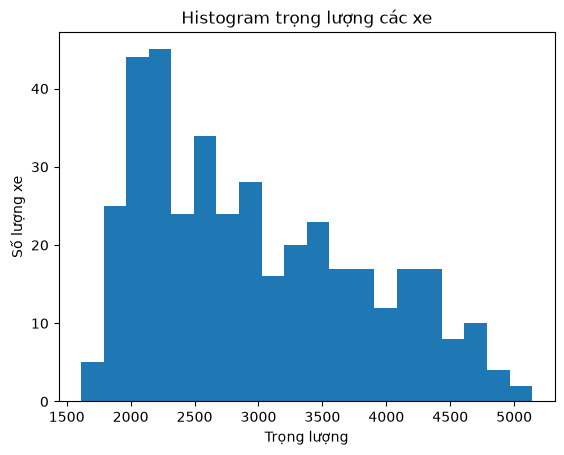

In [7]:
plt.hist(df['weight'], bins=20)

plt.xlabel('Trọng lượng')
plt.ylabel('Số lượng xe')
plt.title('Histogram trọng lượng các xe')
plt.show()


## 5. TÍNH TỶ LỆ CÁC DÒNG XE DỰA TRÊN XUẤT XỨ

In [9]:
print(df['origin'].value_counts(normalize=True) * 100)



origin
usa       62.500000
japan     20.153061
europe    17.346939
Name: proportion, dtype: float64


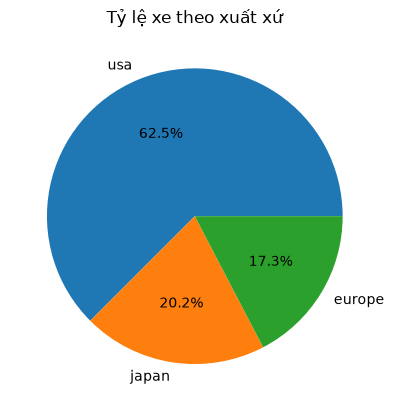

In [10]:
df['origin'].value_counts().plot(kind='pie', autopct='%1.1f%%')

plt.title('Tỷ lệ xe theo xuất xứ')
plt.show()


## 6. VẼ BOXPLOT SO SÁNH CÔNG SUẤT CỦA CÁC DÒNG XE THẬP NIÊN 70, 80

Lưu ý: Các dòng xe thập niên 70 (1970 - 1979), thập niên 80 (1980 - 1989)

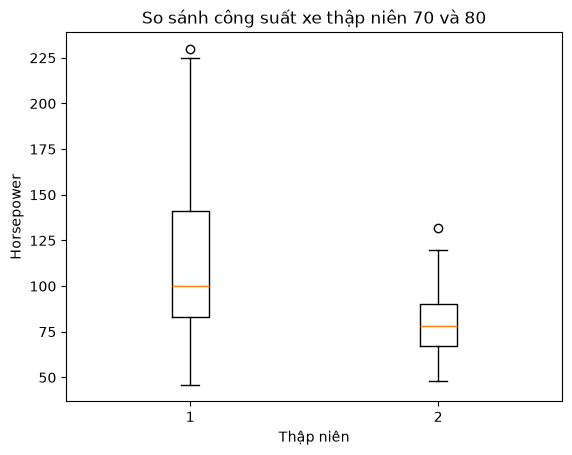

In [11]:
xe70 = df[(df['model_year'] >= 70) & (df['model_year'] <= 79)]

xe80 = df[(df['model_year'] >= 80) & (df['model_year'] <= 89)]
data = [xe70['horsepower'], xe80['horsepower']]
plt.boxplot(data)

plt.xlabel('Thập niên')
plt.ylabel('Horsepower')
plt.title('So sánh công suất xe thập niên 70 và 80')
plt.show()


## 7. KHẢO SÁT MỨC TIÊU HAO NHIÊN LIỆU

### 7.1 Với số lượng xi lanh

Thử vẽ bằng đồ thị scatter plot.

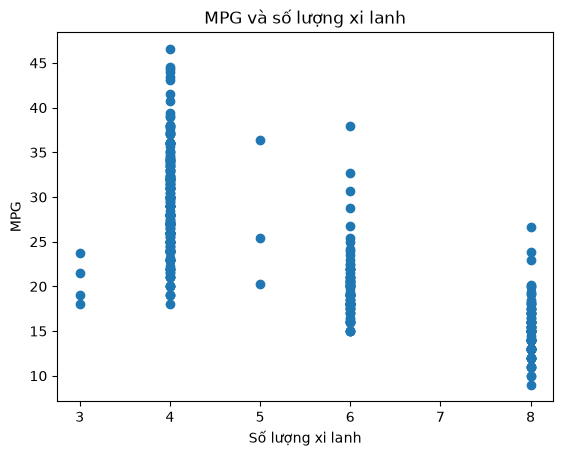

In [12]:
plt.scatter(df['cylinders'], df['mpg'])

plt.xlabel('Số lượng xi lanh')
plt.ylabel('MPG')
plt.title('MPG và số lượng xi lanh')
plt.show()


### 7.2 Với công suất theo mã lực

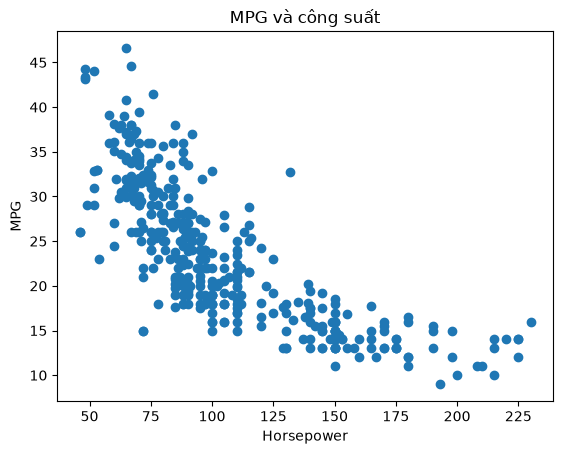

In [13]:
plt.scatter(df['horsepower'], df['mpg'])

plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.title('MPG và công suất')
plt.show()


### 7.3 Với gia tốc

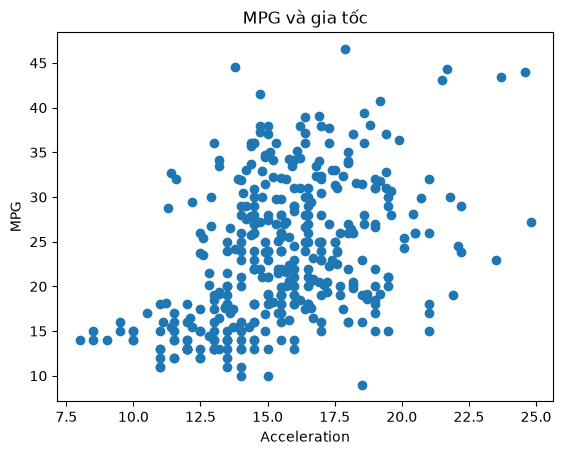

In [14]:
plt.scatter(df['acceleration'], df['mpg'])

plt.xlabel('Acceleration')
plt.ylabel('MPG')
plt.title('MPG và gia tốc')
plt.show()


### 7.4 Với năm sản xuất

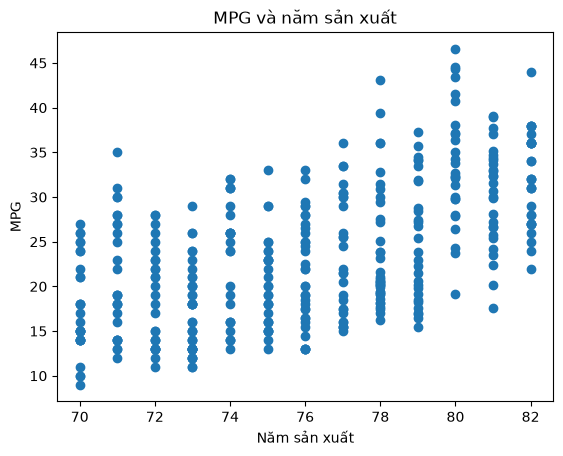

In [15]:
plt.scatter(df['model_year'], df['mpg'])

plt.xlabel('Năm sản xuất')
plt.ylabel('MPG')
plt.title('MPG và năm sản xuất')
plt.show()
